In [1]:
import os
import h5py
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path
from CNC_Machining.utils import data_loader_utils

In [2]:
data_path = Path(str(Path("./").absolute())+"/CNC_Machining/data")
data_dist = data_loader_utils.get_file_labels(data_path)

print(data_path)

/home/scopellie/EECE5644/Project/CNC_Machining/data


In [3]:
df = pd.DataFrame(data_dist, columns=["Machine","Operation","Good","Bad"])
df["Total"] = df["Good"] + df["Bad"]

df.head()

,Machine,Operation,Good,Bad,Total
0,M01,OP00,29,0,29
1,M01,OP01,38,2,40
2,M01,OP02,45,1,46
3,M01,OP03,27,1,28
4,M01,OP04,34,2,36


In [16]:
filelist = data_loader_utils.find_all_h5s_in_dir(data_path)
df_m = pd.DataFrame(columns=["timestamp","X","Y","Z","filename","label"])

for file in filelist[:5]:
    with h5py.File(file, 'r') as f:
        dataset = f['vibration_data'][:]
        df = pd.DataFrame(dataset, columns=["X","Y","Z"])
        
        df["timestamp"] = np.arange(len(df)) * 0.5
        file_name = str(file).split("/")[-1]
        label = str(file).split("/")[-2]
        df["filename"] = file_name
        df["label"] = label
        df["window"] = df["timestamp"] // 2000 # Windows with 4000 records, ~2s
        
        df_m = pd.concat([df_m, df], ignore_index=True)
        
print(f"Shape of the Dataframe: {df_m.shape} \n")
df_m = df_m.convert_dtypes()
#df_m.info()
df_m

Shape of the Dataframe: (456704, 7) 



,timestamp,X,Y,Z,filename,label,window
0,0.0,-15,25,-1013,M01_Aug_2019_OP02_013.h5,good,0
1,0.5,-21,19,-1013,M01_Aug_2019_OP02_013.h5,good,0
2,1.0,-17,29,-1013,M01_Aug_2019_OP02_013.h5,good,0
3,1.5,-13,13,-1013,M01_Aug_2019_OP02_013.h5,good,0
4,2.0,-9,25,-1020,M01_Aug_2019_OP02_013.h5,good,0
...,...,...,...,...,...,...,...
456699,47613.5,-13,17,-1024,M01_Aug_2019_OP02_008.h5,good,23
456700,47614.0,-19,27,-1018,M01_Aug_2019_OP02_008.h5,good,23
456701,47614.5,-17,31,-1015,M01_Aug_2019_OP02_008.h5,good,23
456702,47615.0,-7,23,-1020,M01_Aug_2019_OP02_008.h5,good,23


array([<Axes: xlabel='timestamp'>, <Axes: xlabel='timestamp'>,
       <Axes: xlabel='timestamp'>], dtype=object)

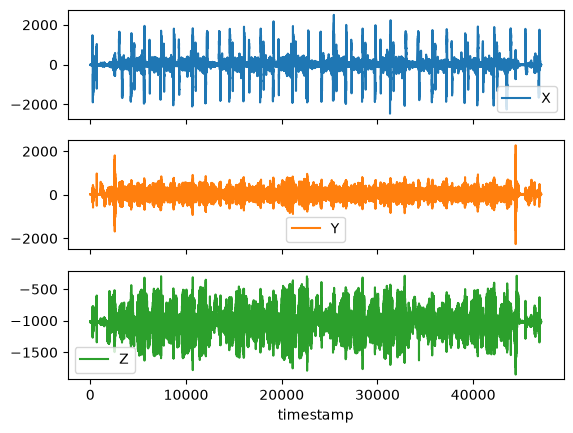

In [17]:
columns = df_m.columns

# File 1
fname = "M01_Aug_2019_OP02_013.h5"
df1 = df_m[df_m["filename"] == fname]

df1.plot(x="timestamp", y=columns[1:4], subplots=True)

<class 'pandas.DataFrame'>
RangeIndex: 94208 entries, 0 to 94207
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  94208 non-null  Float64
 1   X          94208 non-null  Int64  
 2   Y          94208 non-null  Int64  
 3   Z          94208 non-null  Int64  
 4   filename   94208 non-null  string 
 5   label      94208 non-null  string 
 6   window     94208 non-null  Int64  
dtypes: Float64(1), Int64(4), string(2)
memory usage: 5.5 MB


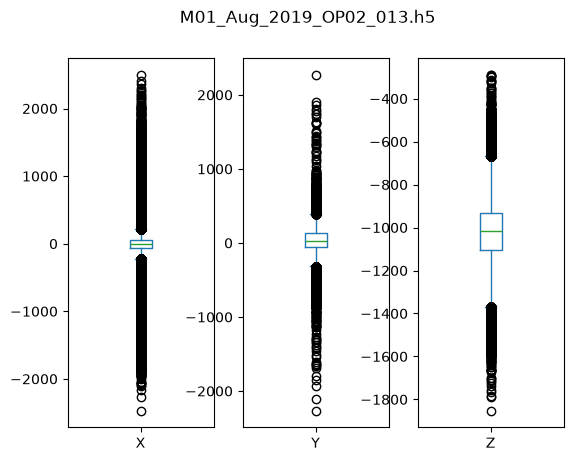

In [ ]:
df1.plot(x="timestamp", y=columns[1:4], title=fname, subplots=True, kind="box")
df1.info()